# Corrigé du TP4 : tableau de bord d'indicateurs

## Objectifs

- construire et personnaliser des graphiques avec matplotlib : courbes, barres, histogrammes, nuages de points, grilles de graphiques
- ajouter des repères à un graphique : ligne d'objectif, labels de valeurs, annotations
- produire des graphiques statistiques avec seaborn
- créer des graphiques interactifs avec plotly et les exporter en HTML
- repérer et corriger des graphiques trompeurs ou mal construits
- assembler un tableau de bord qui applique les bonnes pratiques de dataviz

## Livrable

- ce notebook de restitution, avec un tableau de bord de 4 à 5 graphiques commentés, dont au moins un avec seaborn et un interactif avec plotly
- l'export HTML du graphique interactif principal, `ca_mensuel_regions.html`
- la figure `activite_mensuelle.png`

## Les données

Les deux tables produites au TP3 :

- `indicateurs_mois_region.parquet` : une ligne par mois et par région
- `ventes_consolidees.parquet` : une ligne par commande

Une version est fournie dans `ressources/`. Tu peux utiliser les tiennes à la place en modifiant la variable `DOSSIER`.

## Comment travailler

- Le TP suit le cours : chaque partie se fait juste après la section du cours correspondante.
- Complète les cellules marquées `# TODO`, en utilisant les noms de variables indiqués dans l'énoncé.
- Quand un **résultat attendu** est indiqué, compare-le avec ce que tu obtiens. Pour un graphique, le résultat attendu est une image : ton graphique doit lui ressembler, sans être identique au pixel près.
- Les cellules qui commencent par `# Vérification` contrôlent ton travail avec `assert` : exécute-les sans les modifier. Si tout est juste, elles affichent `OK` ; sinon, elles s'arrêtent sur une `AssertionError` dont le message indique ce qui ne va pas. Pour les graphiques, elles inspectent la figure `fig` et le graphique `ax` (ou `axes`) : garde ces noms.
- Les questions **Pour aller plus loin** sont facultatives : fais-les si tu as terminé une partie en avance.

## Partie 0 : environnement et données

*À faire après la section 1 du cours : les données et l'environnement.*

Active l'environnement virtuel des TP précédents, ou recrée-en un dans ce dossier avec `python3 -m venv .venv`, puis `python -m pip install -r ../tp01-environnement-pandas/requirements.txt`. Ajoute ensuite les bibliothèques de visualisation et mets à jour le `requirements.txt` :

```bash
python -m pip install matplotlib seaborn plotly
python -m pip freeze > requirements.txt
```

Lance `jupyter lab` depuis le dossier de ce TP, puis exécute la cellule suivante : elle importe les bibliothèques et charge les deux tables.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import seaborn as sns
from matplotlib.ticker import FuncFormatter

DOSSIER = Path("ressources")   # ou Path("../tp03-indicateurs") pour utiliser tes propres fichiers

indicateurs = pd.read_parquet(DOSSIER / "indicateurs_mois_region.parquet")
ventes = pd.read_parquet(DOSSIER / "ventes_consolidees.parquet")
indicateurs.head()


,mois,region,ca,nb_commandes,panier_moyen,quantite,objectif_mensuel,taux_realisation
0,2025-01-01,Auvergne-Rhône-Alpes,9608.29,45,213.517556,224,8500,1.130387
1,2025-01-01,Bretagne,3015.50,22,137.068182,115,4500,0.670111
2,2025-01-01,Hauts-de-France,3655.89,24,152.328750,103,6500,0.562445
3,2025-01-01,Nouvelle-Aquitaine,6524.88,32,203.902500,198,7000,0.932126
4,2025-01-01,Occitanie,4878.14,31,157.359355,120,6500,0.750483


### Question 0.1

Affiche les dimensions des deux tables, le premier et le dernier mois de `indicateurs` (`min` et `max`), puis la liste triée des régions (`unique`, puis `sorted`).

**Résultat attendu** :

```text
(54, 8) (2182, 15)
2025-01-01 00:00:00 2025-09-01 00:00:00
['Auvergne-Rhône-Alpes', 'Bretagne', 'Hauts-de-France', 'Nouvelle-Aquitaine', 'Occitanie', 'Île-de-France']
```

In [2]:
print(indicateurs.shape, ventes.shape)
print(indicateurs["mois"].min(), indicateurs["mois"].max())
print(sorted(indicateurs["region"].unique()))


(54, 8) (2182, 15)
2025-01-01 00:00:00 2025-09-01 00:00:00
['Auvergne-Rhône-Alpes', 'Bretagne', 'Hauts-de-France', 'Nouvelle-Aquitaine', 'Occitanie', 'Île-de-France']


### Question 0.2

Les graphiques de ce TP reviennent souvent aux mêmes agrégats. Calcule :

- `mensuel` : le chiffre d'affaires total de chaque mois, toutes régions confondues ;
- `par_region` : le chiffre d'affaires total de chaque région sur les neuf mois, trié par ordre croissant.

Affiche-les.

**Résultat attendu** :

```text
mois
2025-01-01    43475.13
2025-02-01    37830.25
2025-03-01    53471.97
2025-04-01    56339.59
2025-05-01    48801.55
2025-06-01    52362.65
2025-07-01    31873.02
2025-08-01    27273.63
2025-09-01    58073.80
Name: ca, dtype: float64
region
Bretagne                 41079.71
Occitanie                50318.18
Hauts-de-France          53467.33
Auvergne-Rhône-Alpes     64856.25
Nouvelle-Aquitaine       71843.18
Île-de-France           127936.94
Name: ca, dtype: float64
```

In [3]:
mensuel = indicateurs.groupby("mois")["ca"].sum()
par_region = indicateurs.groupby("region")["ca"].sum().sort_values()
print(mensuel)
print(par_region)


mois
2025-01-01    43475.13
2025-02-01    37830.25
2025-03-01    53471.97
2025-04-01    56339.59
2025-05-01    48801.55
2025-06-01    52362.65
2025-07-01    31873.02
2025-08-01    27273.63
2025-09-01    58073.80
Name: ca, dtype: float64
region
Bretagne                 41079.71
Occitanie                50318.18
Hauts-de-France          53467.33
Auvergne-Rhône-Alpes     64856.25
Nouvelle-Aquitaine       71843.18
Île-de-France           127936.94
Name: ca, dtype: float64


In [4]:
# Vérification
assert len(mensuel) == 9, "mensuel doit contenir une valeur par mois, soit 9 valeurs"
assert round(mensuel.sum(), 2) == round(indicateurs["ca"].sum(), 2), "le total de mensuel doit être égal au chiffre d'affaires total"
assert len(par_region) == 6, "par_region doit contenir les 6 régions"
assert list(par_region) == sorted(par_region), "par_region doit être trié par ordre croissant"
print("Question 0.2 : OK")


Question 0.2 : OK


## Partie 1 : matplotlib

*À faire après la section 2 du cours : matplotlib.*

Chaque graphique se crée avec `fig, ax = plt.subplots(figsize=...)`, en reprenant la taille indiquée pour obtenir un résultat comparable à l'image attendue.

### Question 1.1

Trace l'évolution du chiffre d'affaires mensuel (`mensuel`) avec une courbe et des marqueurs ronds, dans `fig, ax = plt.subplots(figsize=(8, 4))`. Ajoute :

- un titre, et un nom à l'axe vertical avec son unité ;
- un axe vertical qui part de zéro ;
- des montants affichés en milliers d'euros, grâce à un formateur `FuncFormatter` rangé dans une variable `milliers`, que tu réutiliseras dans la suite du TP ;
- une grille horizontale discrète.

**Résultat attendu** :

![Résultat attendu de la question 1.1](attendus/q1_1.png)

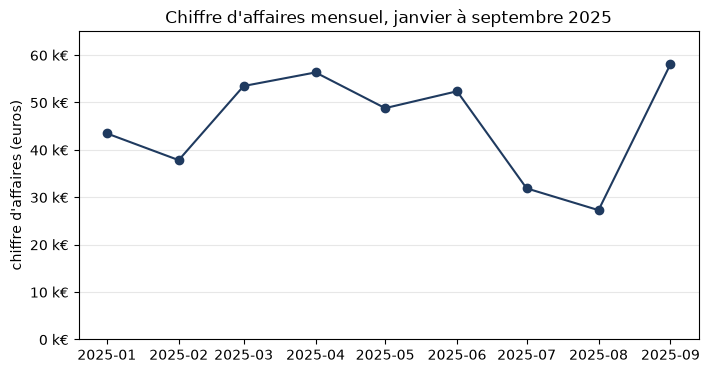

In [5]:
milliers = FuncFormatter(lambda v, _: f"{v / 1000:.0f} k€")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mensuel.index, mensuel.values, marker="o", color="#1F3A5F")
ax.set_title("Chiffre d'affaires mensuel, janvier à septembre 2025")
ax.set_ylabel("chiffre d'affaires (euros)")
ax.set_ylim(0, 65000)
ax.yaxis.set_major_formatter(milliers)
ax.grid(axis="y", alpha=0.3)


In [6]:
# Vérification
assert ax.get_title() != "", "le graphique doit avoir un titre"
assert ax.get_ylabel() != "", "l'axe vertical doit être nommé, avec son unité"
assert len(ax.lines) == 1 and len(ax.lines[0].get_xdata()) == 9, "il faut une seule courbe, avec un point par mois"
assert ax.get_ylim()[0] == 0, "l'axe vertical doit partir de zéro : ax.set_ylim(0, ...)"
assert ax.get_ylim()[1] >= mensuel.max(), "l'axe vertical doit monter au moins jusqu'au meilleur mois"
assert "k" in ax.yaxis.get_major_formatter()(20000, 0), "les montants doivent être affichés en milliers, par exemple 20 k€"
print("Question 1.1 : OK")


Question 1.1 : OK


### Question 1.2

Trace maintenant le chiffre d'affaires mensuel en barres verticales, dans `fig, ax = plt.subplots(figsize=(8, 4))`. Pour que les barres aient une largeur normale, place-les sur des labels texte : `etiquettes = mensuel.index.strftime("%m/%y")`.

Calcule ensuite dans `objectif_total` l'objectif mensuel de l'ensemble des régions, c'est-à-dire la somme des objectifs mensuels des six régions pour un mois. Trace-le comme une ligne horizontale en pointillés (`ax.axhline`), donne un `label` aux barres et à la ligne, et affiche la légende en haut à gauche, sur deux colonnes, en laissant de la place au-dessus des barres (axe vertical jusqu'à 70 000 euros). Réutilise le formateur `milliers`.

Affiche enfin la valeur de `objectif_total` et la liste des mois qui dépassent l'objectif. Combien y en a-t-il ?

Indice : `indicateurs.groupby("mois")["objectif_mensuel"].sum()` donne l'objectif total de chaque mois.

**Résultat attendu** :

![Résultat attendu de la question 1.2](attendus/q1_2.png)

objectif : 47000
['03/25', '04/25', '05/25', '06/25', '09/25']


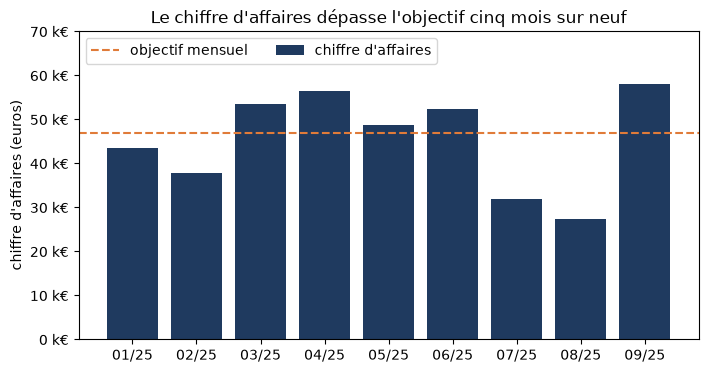

In [7]:
etiquettes = mensuel.index.strftime("%m/%y")
objectif_total = indicateurs.groupby("mois")["objectif_mensuel"].sum().iloc[0]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(etiquettes, mensuel.values, color="#1F3A5F", label="chiffre d'affaires")
ax.axhline(objectif_total, color="#E07B39", linestyle="--", label="objectif mensuel")
ax.set_title("Le chiffre d'affaires dépasse l'objectif cinq mois sur neuf")
ax.set_ylabel("chiffre d'affaires (euros)")
ax.set_ylim(0, 70000)
ax.yaxis.set_major_formatter(milliers)
ax.legend(loc="upper left", ncols=2)

print("objectif :", objectif_total)
print(list(etiquettes[mensuel.values > objectif_total]))


In [8]:
# Vérification
assert len(ax.patches) == 9, "il faut une barre par mois, soit 9 barres"
assert ax.get_ylim()[0] == 0, "l'axe vertical d'un graphique en barres doit partir de zéro"
assert objectif_total == 47000, "l'objectif total est la somme des objectifs mensuels des six régions"
assert any(set(ligne.get_ydata()) == {objectif_total} for ligne in ax.lines), "trace l'objectif avec ax.axhline(objectif_total, ...)"
assert ax.get_legend() is not None, "affiche la légende avec ax.legend()"
print("Question 1.2 : OK")


Question 1.2 : OK


**Réponse** : L'objectif total vaut 47 000 euros par mois. Cinq mois le dépassent : mars, avril, mai, juin et septembre. Janvier et février sont un peu en dessous, juillet et août nettement.

### Question 1.3

Trace le chiffre d'affaires total par région (`par_region`) en barres horizontales, dans `fig, ax = plt.subplots(figsize=(8, 4))`, avec la plus grande barre en haut.

- Mets en évidence la région la plus forte avec une couleur, et les autres en gris : construis la liste `couleurs` avec une compréhension et `par_region.idxmax()`.
- Écris un titre qui énonce le message du graphique, et nomme l'axe horizontal.
- Affiche au bout de chaque barre son montant en milliers d'euros avec `ax.bar_label`, et prolonge l'axe horizontal jusqu'à 145 000 euros (`ax.set_xlim`) pour laisser de la place aux labels.

**Résultat attendu** :

![Résultat attendu de la question 1.3](attendus/q1_3.png)

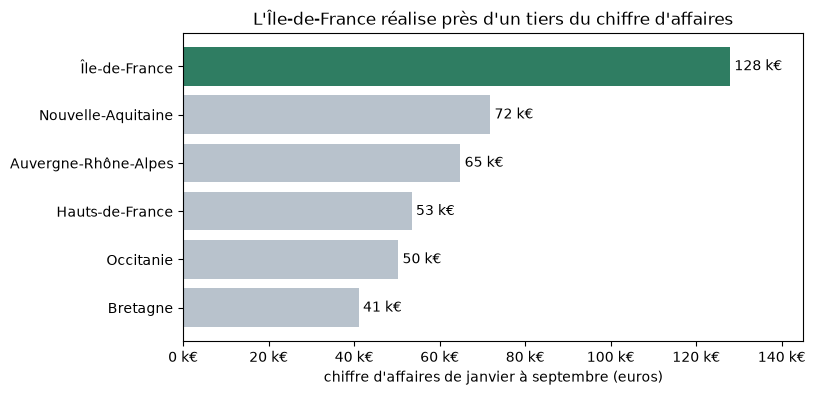

In [9]:
couleurs = ["#2F7D62" if r == par_region.idxmax() else "#B8C2CC" for r in par_region.index]

fig, ax = plt.subplots(figsize=(8, 4))
barres = ax.barh(par_region.index, par_region.values, color=couleurs)
ax.bar_label(barres, labels=[f"{v / 1000:.0f} k€" for v in par_region.values], padding=3)
ax.set_title("L'Île-de-France réalise près d'un tiers du chiffre d'affaires")
ax.set_xlabel("chiffre d'affaires de janvier à septembre (euros)")
ax.set_xlim(0, 145000)
ax.xaxis.set_major_formatter(milliers)


In [10]:
# Vérification
largeurs = [barre.get_width() for barre in ax.patches]
assert len(largeurs) == 6, "il faut une barre par région"
assert largeurs == sorted(largeurs), "la plus grande barre doit être en haut : trace par_region, trié par ordre croissant"
assert len({barre.get_facecolor() for barre in ax.patches}) == 2, "deux couleurs seulement : une pour la région la plus forte, du gris pour les autres"
assert ax.patches[-1].get_facecolor() != ax.patches[0].get_facecolor(), "c'est la région la plus forte, en haut, qui doit être mise en évidence"
assert len(ax.texts) == 6, "ajoute un label par barre avec ax.bar_label"
assert ax.get_title() != "" and ax.get_xlabel() != "", "il faut un titre et un axe horizontal nommé"
print("Question 1.3 : OK")


Question 1.3 : OK


### Question 1.4

Calcule dans `commandes` le nombre total de commandes de chaque mois. Dans une même figure, `fig, axes = plt.subplots(1, 2, figsize=(11, 4))`, place côte à côte le chiffre d'affaires mensuel et le nombre de commandes mensuel, en barres, chacun avec un titre. Utilise `fig.tight_layout()`, puis enregistre la figure en `activite_mensuelle.png`.

Le creux de l'été vient-il d'une baisse du nombre de commandes, ou d'une baisse du montant de chaque commande ?

**Résultat attendu** :

![Résultat attendu de la question 1.4](attendus/q1_4.png)

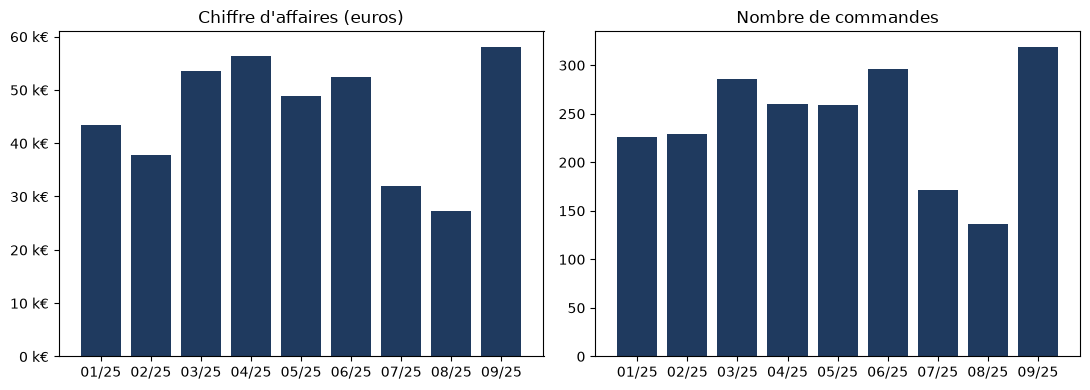

In [11]:
commandes = indicateurs.groupby("mois")["nb_commandes"].sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(etiquettes, mensuel.values, color="#1F3A5F")
axes[0].set_title("Chiffre d'affaires (euros)")
axes[0].yaxis.set_major_formatter(milliers)
axes[1].bar(etiquettes, commandes.values, color="#1F3A5F")
axes[1].set_title("Nombre de commandes")
fig.tight_layout()
fig.savefig("activite_mensuelle.png", dpi=150, bbox_inches="tight")


In [12]:
# Vérification
assert commandes.sum() == indicateurs["nb_commandes"].sum(), "commandes doit contenir le nombre total de commandes de chaque mois"
assert len(fig.axes) == 2, "la figure doit contenir deux graphiques côte à côte"
assert [len(graphique.patches) for graphique in fig.axes] == [9, 9], "chaque graphique doit avoir une barre par mois"
assert all(graphique.get_title() != "" for graphique in fig.axes), "chaque graphique doit avoir un titre"
assert Path("activite_mensuelle.png").exists(), "enregistre la figure avec fig.savefig"
print("Question 1.4 : OK")


Question 1.4 : OK


**Réponse** : D'une baisse du nombre de commandes : on passe de près de 300 commandes en juin à 171 en juillet et 136 en août. Les deux graphiques ont la même forme, le montant moyen d'une commande reste donc stable (186 euros en juillet, 200 euros en août, pour une moyenne de 188 euros sur la période).

### Question 1.5

Trace avec `ax.hist` l'histogramme du taux de réalisation de l'objectif (`taux_realisation`) des 54 couples mois et région, dans `fig, ax = plt.subplots(figsize=(8, 4))`. Utilise des classes de 10 points, de 20 % à 180 % : passe à `bins` la liste des bornes, construite avec une compréhension, `[x / 10 for x in range(2, 19)]`.

Ajoute une ligne verticale à 100 % (`ax.axvline`) avec une légende, nomme les deux axes et affiche les taux en pourcentage avec un formateur. Combien de couples mois et région atteignent leur objectif ?

**Résultat attendu** :

![Résultat attendu de la question 1.5](attendus/q1_5.png)

25 sur 54


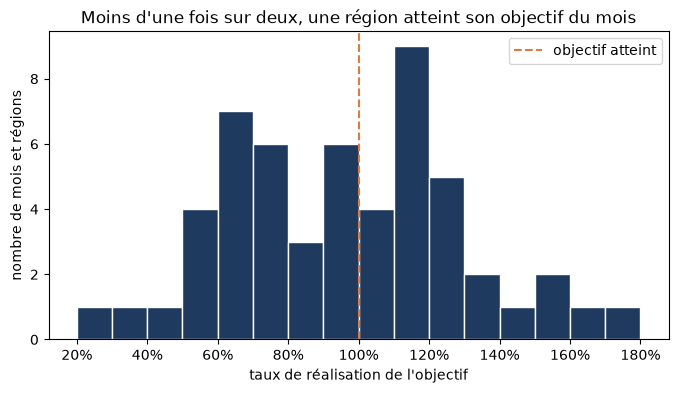

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(indicateurs["taux_realisation"], bins=[x / 10 for x in range(2, 19)], color="#1F3A5F", edgecolor="white")
ax.axvline(1, color="#E07B39", linestyle="--", label="objectif atteint")
ax.set_title("Moins d'une fois sur deux, une région atteint son objectif du mois")
ax.set_xlabel("taux de réalisation de l'objectif")
ax.set_ylabel("nombre de mois et régions")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend()

print((indicateurs["taux_realisation"] >= 1).sum(), "sur", len(indicateurs))


In [14]:
# Vérification
assert len(ax.patches) == 16, "il faut 16 classes de 10 points, de 20 % à 180 %"
assert sum(barre.get_height() for barre in ax.patches) == 54, "l'histogramme doit compter les 54 couples mois et région"
assert any(set(ligne.get_xdata()) == {1} for ligne in ax.lines), "trace la ligne de l'objectif avec ax.axvline(1, ...)"
assert ax.get_xlabel() != "" and ax.get_ylabel() != "", "nomme les deux axes"
print("Question 1.5 : OK")


Question 1.5 : OK


**Réponse** : 25 couples mois et région sur 54 atteignent leur objectif, soit moins d'un sur deux. La distribution est large : de moins de 30 % à plus de 170 % de l'objectif.

### Question 1.6

Trace avec `ax.scatter` le chiffre d'affaires de chaque couple mois et région en fonction de son nombre de commandes, dans `fig, ax = plt.subplots(figsize=(8, 4))`. Rends les points semi-transparents (`alpha=0.7`), nomme les axes et donne un titre. Les deux grandeurs sont-elles liées ?

**Résultat attendu** :

![Résultat attendu de la question 1.6](attendus/q1_6.png)

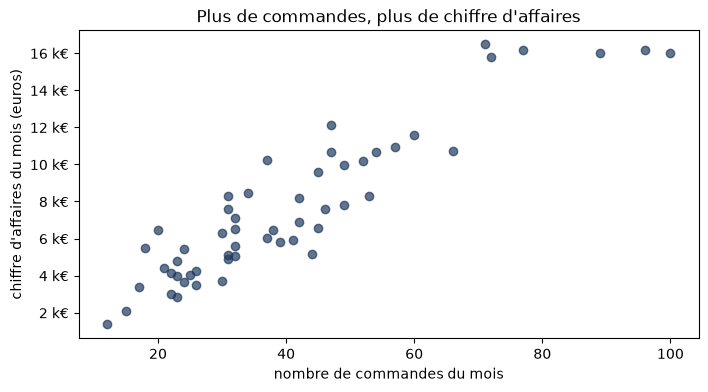

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(indicateurs["nb_commandes"], indicateurs["ca"], color="#1F3A5F", alpha=0.7)
ax.set_title("Plus de commandes, plus de chiffre d'affaires")
ax.set_xlabel("nombre de commandes du mois")
ax.set_ylabel("chiffre d'affaires du mois (euros)")
ax.yaxis.set_major_formatter(milliers)


In [16]:
# Vérification
assert len(ax.collections) == 1 and len(ax.collections[0].get_offsets()) == 54, "il faut un point par couple mois et région, soit 54 points"
assert ax.get_xlabel() != "" and ax.get_ylabel() != "", "nomme les deux axes"
assert ax.get_title() != "", "le graphique doit avoir un titre"
print("Question 1.6 : OK")


Question 1.6 : OK


**Réponse** : Oui : dans l'ensemble, plus un mois compte de commandes, plus son chiffre d'affaires est élevé, et les points s'alignent à peu près le long d'une droite qui monte. L'écart des points autour de cette tendance vient du montant moyen des commandes, qui varie d'un mois à l'autre. Les points en haut à droite font exception : au-delà de 70 commandes, le chiffre d'affaires plafonne vers 16 k€.

### Question 1.7

Construis dans `ca_categories` un tableau croisé du chiffre d'affaires de `ventes`, avec les mois en lignes, au format `%m/%y`, et les catégories en colonnes : `pivot_table` avec `index=ventes["date"].dt.strftime("%m/%y")`, `columns="categorie"`, `values="montant"` et `aggfunc="sum"`.

Trace ensuite, dans une grille de 2 lignes et 2 colonnes qui partagent la même échelle verticale, `fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharey=True)`, un graphique en barres par catégorie pour les quatre catégories `Informatique`, `Bureau`, `Papeterie` et `Électroménager`, chacun avec le nom de sa catégorie en titre. Donne un titre à la figure avec `fig.suptitle`.

Pourquoi `sharey=True` est-il indispensable ici ?

Indice : une boucle `for ax, categorie in zip(axes.flat, categories):` parcourt les quatre graphiques de la grille en même temps que les catégories.

**Résultat attendu** :

![Résultat attendu de la question 1.7](attendus/q1_7.png)

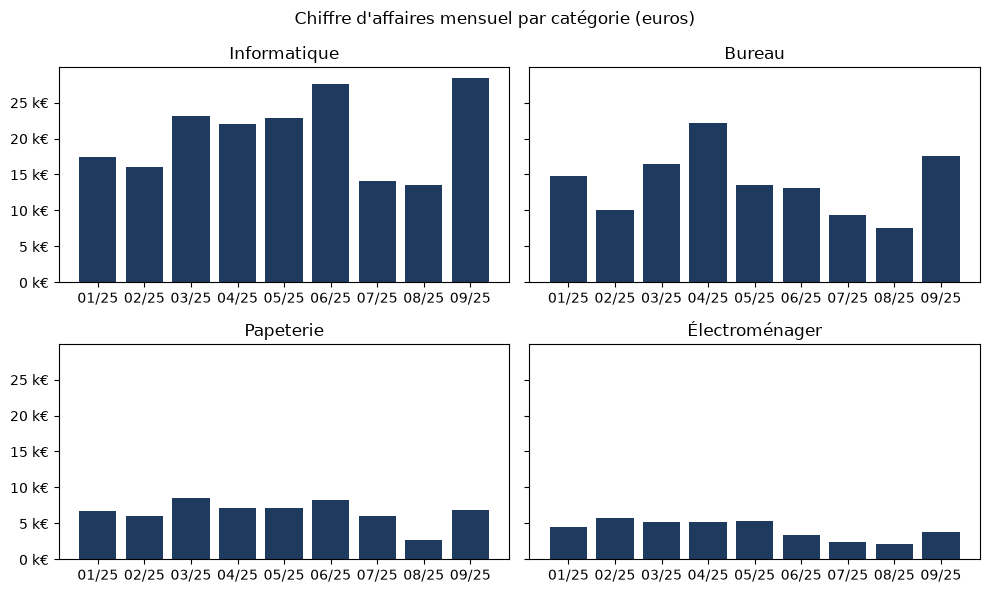

In [17]:
ca_categories = ventes.pivot_table(
    index=ventes["date"].dt.strftime("%m/%y"),
    columns="categorie",
    values="montant",
    aggfunc="sum",
)
categories = ["Informatique", "Bureau", "Papeterie", "Électroménager"]

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharey=True)
for ax, categorie in zip(axes.flat, categories):
    ax.bar(ca_categories.index, ca_categories[categorie], color="#1F3A5F")
    ax.set_title(categorie)
    ax.yaxis.set_major_formatter(milliers)
fig.suptitle("Chiffre d'affaires mensuel par catégorie (euros)")
fig.tight_layout()


In [18]:
# Vérification
assert ca_categories.shape == (9, 5), "ca_categories doit avoir 9 mois en lignes et 5 catégories en colonnes"
assert round(ca_categories.sum().sum(), 2) == round(ventes["montant"].sum(), 2), "le tableau doit contenir tout le chiffre d'affaires"
assert len(fig.axes) == 4, "la grille doit contenir 4 graphiques"
assert len({graphique.get_ylim() for graphique in fig.axes}) == 1, "les 4 graphiques doivent partager la même échelle verticale : sharey=True"
assert all(graphique.get_title() != "" for graphique in fig.axes), "chaque graphique doit avoir le nom de sa catégorie en titre"
print("Question 1.7 : OK")


Question 1.7 : OK


**Réponse** : Sans `sharey=True`, chaque graphique aurait sa propre échelle et toutes les barres sembleraient de même hauteur : l'électroménager, qui fait environ cinq fois moins de chiffre d'affaires que l'informatique, paraîtrait aussi important. Avec une échelle commune, on voit tout de suite que l'informatique et le bureau portent l'activité.

### Pour aller plus loin 1.8

Reprends la courbe de la question 1.1 et signale le creux de l'été : colore la période de mi-juin à mi-août avec `ax.axvspan` (bornes `pd.to_datetime("2025-06-15")` et `pd.to_datetime("2025-08-15")`), et ajoute une annotation avec une flèche (`ax.annotate`) qui pointe sur le mois d'août. Change le titre pour qu'il énonce le message.

**Résultat attendu** :

![Résultat attendu de la question 1.8](attendus/q1_8.png)

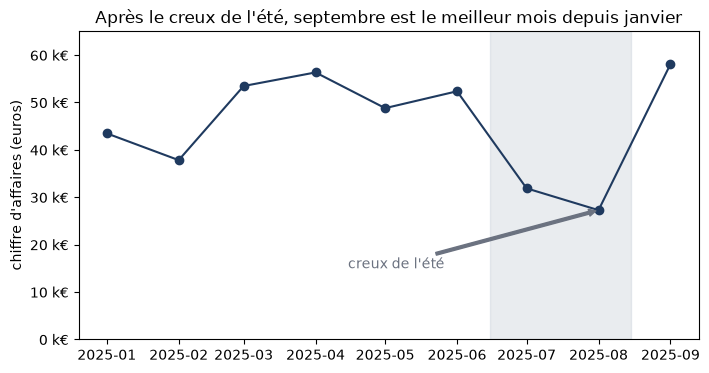

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mensuel.index, mensuel.values, marker="o", color="#1F3A5F")
ax.axvspan(pd.to_datetime("2025-06-15"), pd.to_datetime("2025-08-15"), color="#B8C2CC", alpha=0.3)
ax.annotate(
    "creux de l'été",
    xy=(mensuel.index[7], mensuel.iloc[7]),
    xytext=(pd.to_datetime("2025-04-15"), 15000),
    arrowprops={"arrowstyle": "simple", "color": "#6B7280"},
    color="#6B7280",
)
ax.set_title("Après le creux de l'été, septembre est le meilleur mois depuis janvier")
ax.set_ylabel("chiffre d'affaires (euros)")
ax.set_ylim(0, 65000)
ax.yaxis.set_major_formatter(milliers)


In [20]:
# Vérification
assert len(ax.patches) >= 1, "colore la période de l'été avec ax.axvspan"
assert len(ax.texts) == 1, "ajoute une annotation avec ax.annotate"
print("Question 1.8 : OK")


Question 1.8 : OK


### Pour aller plus loin 1.9

Avec le raccourci de pandas, trace `par_region` en barres horizontales en une seule ligne, dans un `ax` créé avec `fig, ax = plt.subplots(figsize=(8, 4))` : `par_region.plot.barh(ax=ax)`. Ajoute un titre et nomme l'axe horizontal. Que met pandas sur l'axe vertical ?

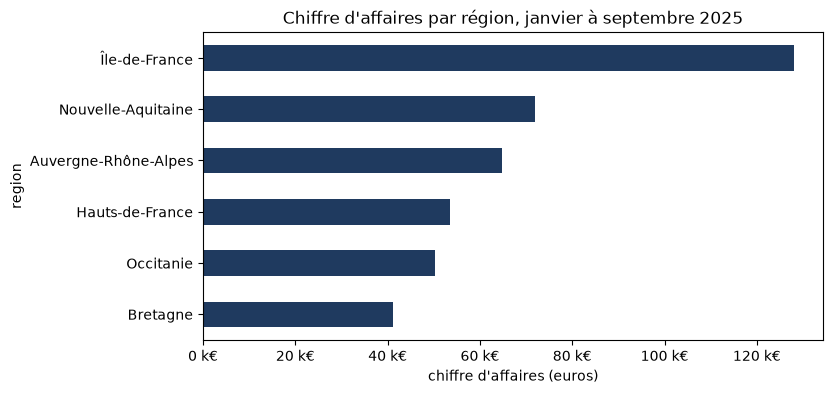

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
par_region.plot.barh(ax=ax, color="#1F3A5F")
ax.set_title("Chiffre d'affaires par région, janvier à septembre 2025")
ax.set_xlabel("chiffre d'affaires (euros)")
ax.xaxis.set_major_formatter(milliers)


In [22]:
# Vérification
assert len(ax.patches) == 6, "il faut une barre par région"
print("Question 1.9 : OK")


Question 1.9 : OK


**Réponse** : pandas place l'index de la Series, les régions, sur l'axe des barres, et nomme cet axe avec le nom de l'index, `region`. Le raccourci est pratique pour explorer ; on personnalise ensuite le graphique avec `ax`, comme d'habitude.

## Partie 2 : seaborn

*À faire après la section 3 du cours : seaborn.*

Exécute la cellule suivante : elle applique un style sobre à tous les graphiques qui suivent, y compris ceux faits avec matplotlib.

In [23]:
sns.set_theme(style="whitegrid")


### Question 2.1

Calcule la moyenne et la médiane du montant des commandes, arrondies à 2 décimales, dans les variables `moyenne` et `mediane`, et affiche-les.

Trace ensuite l'histogramme du montant des commandes avec `sns.histplot` et 40 classes, dans `fig, ax = plt.subplots(figsize=(8, 4))`. Ajoute deux lignes verticales, à la moyenne et à la médiane, avec une légende. Comment qualifierais-tu cette distribution ? Pourquoi la moyenne est-elle si éloignée de la médiane ?

**Résultat attendu** :

![Résultat attendu de la question 2.1](attendus/q2_1.png)

moyenne : 187.67  médiane : 104.7


Text(0, 0.5, 'nombre de commandes')

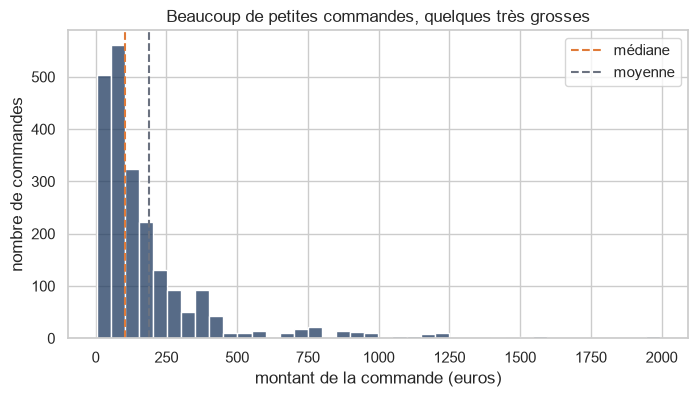

In [24]:
moyenne = round(ventes["montant"].mean(), 2)
mediane = round(ventes["montant"].median(), 2)
print("moyenne :", moyenne, " médiane :", mediane)

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=ventes, x="montant", bins=40, color="#1F3A5F", ax=ax)
ax.axvline(mediane, color="#E07B39", linestyle="--", label="médiane")
ax.axvline(moyenne, color="#6B7280", linestyle="--", label="moyenne")
ax.legend()
ax.set_title("Beaucoup de petites commandes, quelques très grosses")
ax.set_xlabel("montant de la commande (euros)")
ax.set_ylabel("nombre de commandes")


In [25]:
# Vérification
assert moyenne == 187.67 and mediane == 104.7, "calcule la moyenne et la médiane des montants, arrondies à 2 décimales"
assert len(ax.patches) == 40, "l'histogramme doit avoir 40 classes : bins=40"
assert len(ax.lines) >= 2, "ajoute les deux lignes verticales avec ax.axvline"
assert ax.get_title() != "" and ax.get_xlabel() != "", "il faut un titre et un axe horizontal nommé"
print("Question 2.1 : OK")


Question 2.1 : OK


**Réponse** : La distribution est très asymétrique, étirée vers la droite : les trois quarts des commandes font moins de 220 euros, et quelques-unes approchent 2 000 euros. Ces grosses commandes tirent la moyenne (187,67 euros) bien au-dessus de la médiane (104,70 euros). Pour décrire une commande typique, la médiane est plus représentative.

### Question 2.2

Compare la distribution du montant des commandes entre catégories avec une boîte à moustaches, dans `fig, ax = plt.subplots(figsize=(8, 4))`. Range dans `ordre` les catégories triées par médiane décroissante (`groupby`, `median`, `sort_values`, puis `.index`), et passe-le au paramètre `order` de `sns.boxplot`.

Affiche ensuite les commandes de plus de 1 000 euros, comptées par catégorie, produit et quantité (`groupby` sur ces trois colonnes, puis `size()`).

1. Quelle catégorie a les valeurs extrêmes les plus élevées ? À quoi correspondent-elles ?
2. La papeterie a aussi beaucoup de points au-delà de ses moustaches, alors que ses commandes sont modestes. Pourquoi ?

**Résultat attendu** :

![Résultat attendu de la question 2.2](attendus/q2_2.png)

categorie  produit              quantite
Bureau     Bureau assis-debout  3           10
                                4            8
                                5            6
           Chaise ergonomique   5           19
dtype: int64


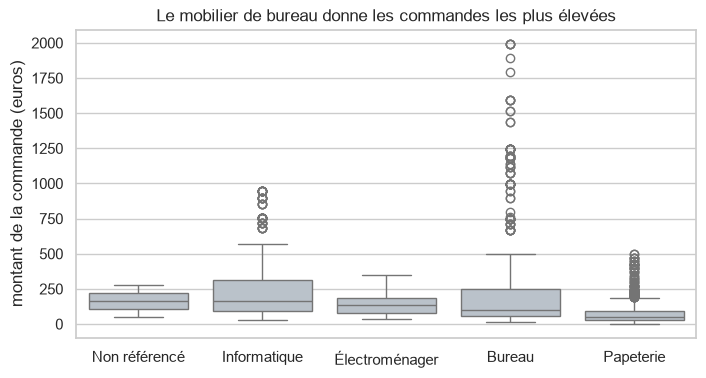

In [26]:
ordre = ventes.groupby("categorie")["montant"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=ventes, x="categorie", y="montant", order=ordre, color="#B8C2CC", ax=ax)
ax.set_title("Le mobilier de bureau donne les commandes les plus élevées")
ax.set_xlabel("")
ax.set_ylabel("montant de la commande (euros)")

grosses = ventes[ventes["montant"] > 1000]
print(grosses.groupby(["categorie", "produit", "quantite"]).size())


In [27]:
# Vérification
assert list(ordre) == ["Non référencé", "Informatique", "Électroménager", "Bureau", "Papeterie"], "les catégories doivent être triées par médiane décroissante"
assert [etiquette.get_text() for etiquette in ax.get_xticklabels()] == list(ordre), "passe ordre au paramètre order de sns.boxplot"
print("Question 2.2 : OK")


Question 2.2 : OK


**Réponse** : Le bureau : ses valeurs extrêmes montent jusqu'à près de 2 000 euros. Les 43 commandes de plus de 1 000 euros sont toutes dans cette catégorie : 24 commandes de 3 à 5 bureaux assis-debout et 19 lots de 5 chaises ergonomiques. La papeterie, elle, a une boîte très étroite : les trois quarts de ses commandes coûtent moins de 95 euros, et ses moustaches s'arrêtent vers 190 euros. Des commandes de 200 à 500 euros, des lots de stylos plume ou d'agrafeuses, y apparaissent donc comme des points isolés. Le nombre de points au-delà des moustaches dépend de la hauteur de la boîte, pas seulement de la taille des commandes.

### Question 2.3

Avec `sns.countplot`, trace le nombre de commandes par catégorie, dans `fig, ax = plt.subplots(figsize=(8, 4))`, de la catégorie la plus fréquente à la moins fréquente : passe au paramètre `order` l'index de `ventes["categorie"].value_counts()`.

**Résultat attendu** :

![Résultat attendu de la question 2.3](attendus/q2_3.png)

Text(0, 0.5, 'nombre de commandes')

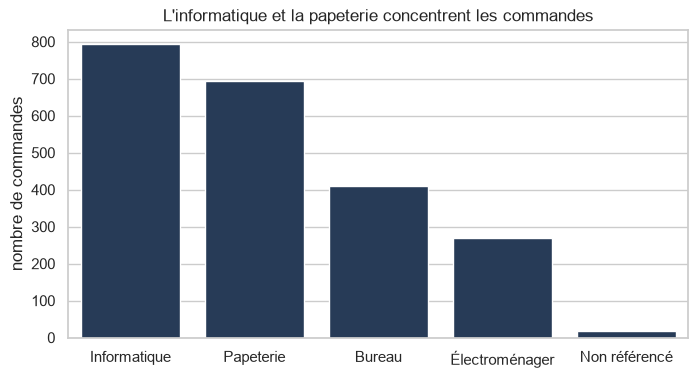

In [28]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=ventes, x="categorie", order=ventes["categorie"].value_counts().index, color="#1F3A5F", ax=ax)
ax.set_title("L'informatique et la papeterie concentrent les commandes")
ax.set_xlabel("")
ax.set_ylabel("nombre de commandes")


In [29]:
# Vérification
hauteurs = [barre.get_height() for barre in ax.patches]
assert len(hauteurs) == 5, "il faut une barre par catégorie"
assert sum(hauteurs) == len(ventes), "countplot compte une ligne par commande"
assert hauteurs == sorted(hauteurs, reverse=True), "les barres doivent aller de la plus haute à la plus basse : paramètre order"
print("Question 2.3 : OK")


Question 2.3 : OK


### Question 2.4

Trace maintenant le chiffre d'affaires par catégorie avec `sns.barplot`, dans `fig, ax = plt.subplots(figsize=(8, 4))` : la somme des montants (`estimator="sum"`), sans trait d'incertitude (`errorbar=None`), et dans le même ordre qu'à la question précédente.

Compare avec le nombre de commandes : que remarques-tu pour la papeterie et pour le bureau ?

**Résultat attendu** :

![Résultat attendu de la question 2.4](attendus/q2_4.png)

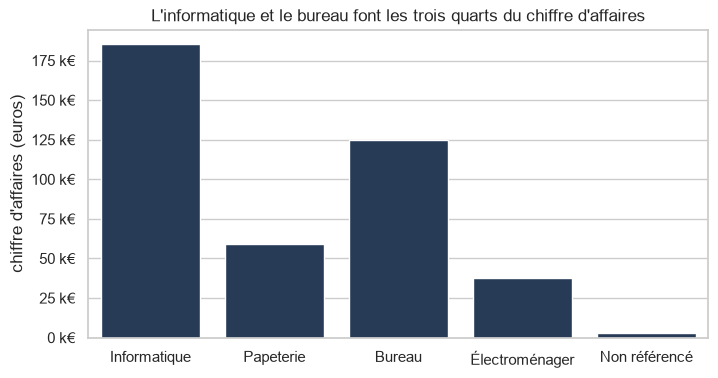

In [30]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    data=ventes,
    x="categorie",
    y="montant",
    estimator="sum",
    errorbar=None,
    order=ventes["categorie"].value_counts().index,
    color="#1F3A5F",
    ax=ax,
)
ax.set_title("L'informatique et le bureau font les trois quarts du chiffre d'affaires")
ax.set_xlabel("")
ax.set_ylabel("chiffre d'affaires (euros)")
ax.yaxis.set_major_formatter(milliers)


In [31]:
# Vérification
hauteurs = [barre.get_height() for barre in ax.patches]
assert len(hauteurs) == 5, "il faut une barre par catégorie"
assert round(sum(hauteurs)) == round(ventes["montant"].sum()), "les barres doivent représenter des totaux : estimator=\"sum\""
assert [etiquette.get_text() for etiquette in ax.get_xticklabels()] == list(ventes["categorie"].value_counts().index), "garde l'ordre de la question précédente"
print("Question 2.4 : OK")


Question 2.4 : OK


**Réponse** : La papeterie est la deuxième catégorie en nombre de commandes (694), mais seulement la troisième en chiffre d'affaires (59 k€, 14 % du total) : ses commandes sont nombreuses mais de faible montant. Le bureau fait l'inverse : presque deux fois moins de commandes (410), mais le deuxième chiffre d'affaires (125 k€, 30 % du total).

### Question 2.5

Avec `sns.lineplot`, trace l'évolution du chiffre d'affaires mensuel de chaque région sur un même graphique (`hue="region"`), avec des marqueurs ronds, dans `fig, ax = plt.subplots(figsize=(8, 4))`. Pour qu'elle ne cache pas les courbes, place la légende à droite du graphique : `sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))`. Ce graphique est-il facile à lire ?

**Résultat attendu** :

![Résultat attendu de la question 2.5](attendus/q2_5.png)

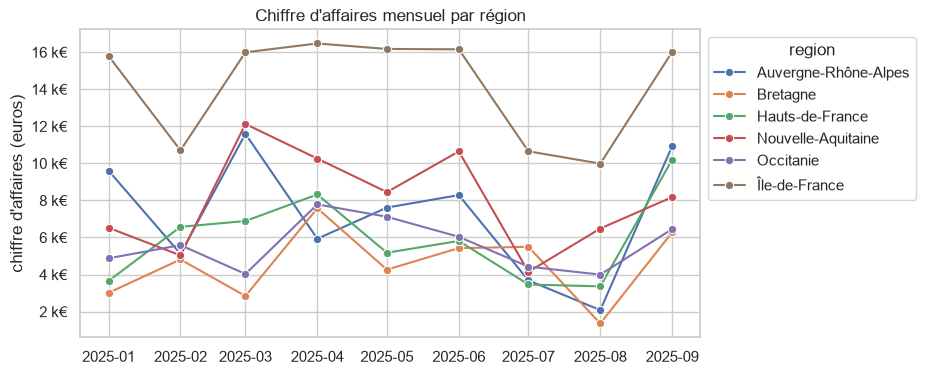

In [32]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.lineplot(data=indicateurs, x="mois", y="ca", hue="region", marker="o", ax=ax)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title("Chiffre d'affaires mensuel par région")
ax.set_xlabel("")
ax.set_ylabel("chiffre d'affaires (euros)")
ax.yaxis.set_major_formatter(milliers)


In [33]:
# Vérification
regions = {texte.get_text() for texte in ax.get_legend().get_texts()}
assert regions == set(indicateurs["region"]), "il faut une courbe par région, avec sa légende : hue=\"region\""
print("Question 2.5 : OK")


Question 2.5 : OK


**Réponse** : Pas vraiment : six courbes qui se croisent forment un « plat de spaghettis ». On distingue l'Île-de-France, nettement au-dessus, mais il est difficile de suivre les autres régions, dont les courbes s'entremêlent entre 1 et 12 k€, et il faut sans cesse faire des allers-retours avec la légende.

### Question 2.6

Avec `sns.relplot`, trace l'évolution du chiffre d'affaires mensuel avec un graphique par région (`col="region"`, `col_wrap=3`, `kind="line"`), dans une variable `g`. Pour une figure compacte, utilise `height=2.8` et `aspect=1.4`, puis titre chaque graphique avec le seul nom de sa région (`g.set_titles("{col_name}")`).

Pourquoi est-ce plus lisible que les six courbes de la question précédente ? Les échelles sont-elles identiques d'un graphique à l'autre ?

**Résultat attendu** :

![Résultat attendu de la question 2.6](attendus/q2_6.png)

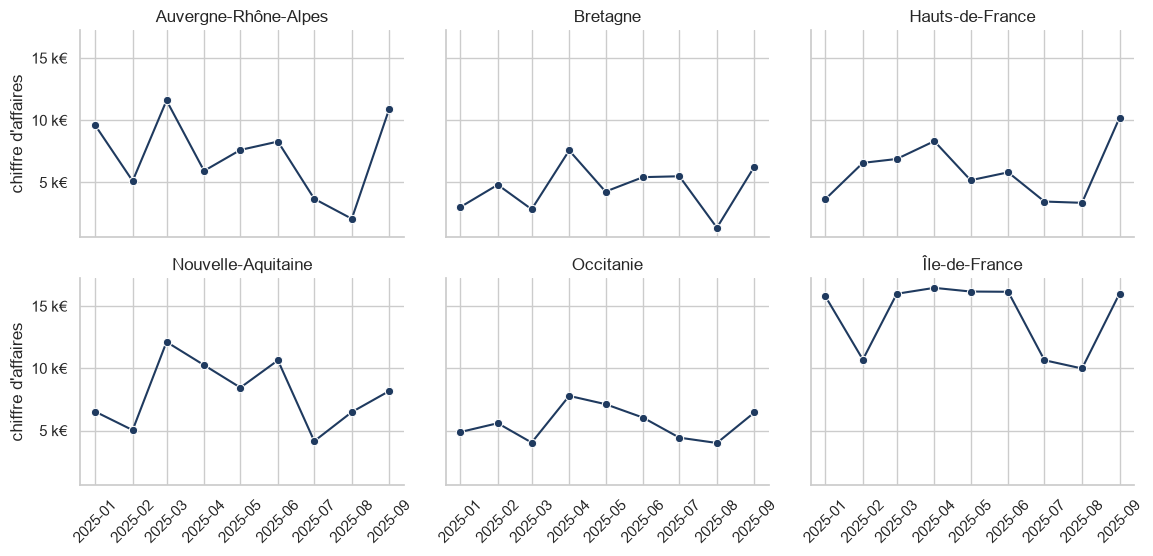

In [34]:
g = sns.relplot(
    data=indicateurs,
    x="mois",
    y="ca",
    col="region",
    col_wrap=3,
    kind="line",
    marker="o",
    color="#1F3A5F",
    height=2.8,
    aspect=1.4,
)
g.set_titles("{col_name}")
g.set_axis_labels("", "chiffre d'affaires")
g.tick_params(axis="x", labelrotation=45)
for graphique in g.axes.flat:
    graphique.yaxis.set_major_formatter(milliers)


In [35]:
# Vérification
assert len(g.axes.flat) == 6, "il faut un graphique par région"
assert len({graphique.get_ylim() for graphique in g.axes.flat}) == 1, "les graphiques doivent partager la même échelle verticale"
print("Question 2.6 : OK")


Question 2.6 : OK


**Réponse** : Chaque courbe se lit seule, sans se mêler aux autres, et on compare facilement les régions d'un graphique à l'autre. `relplot` partage l'échelle verticale par défaut : la comparaison reste juste, et l'Île-de-France apparaît nettement au-dessus des autres régions.

### Question 2.7

Construis dans `taux` une heatmap du taux de réalisation de l'objectif, avec les régions en lignes et les mois en colonnes, au format `%m/%y` : `pivot_table` avec `columns=indicateurs["mois"].dt.strftime("%m/%y")`. Trace-la dans `fig, ax = plt.subplots(figsize=(9, 4))`. Affiche les valeurs en pourcentage et centre la palette sur 100 %, avec une palette lisible par les daltoniens. La barre de couleur est inutile quand les valeurs sont écrites : retire-la avec `cbar=False`.

Quelle région atteint le plus souvent son objectif ? Que se passe-t-il en juillet et en août ?

**Résultat attendu** :

![Résultat attendu de la question 2.7](attendus/q2_7.png)

Text(76.53480360243056, 0.5, '')

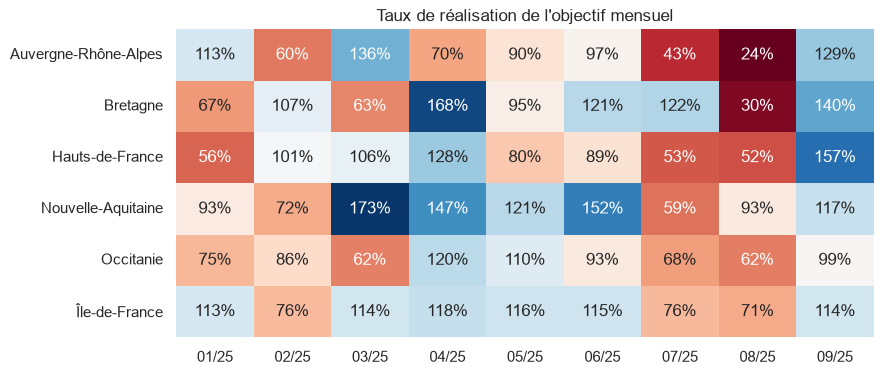

In [36]:
taux = indicateurs.pivot_table(
    index="region",
    columns=indicateurs["mois"].dt.strftime("%m/%y"),
    values="taux_realisation",
)

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(taux, annot=True, fmt=".0%", cmap="RdBu", center=1, cbar=False, ax=ax)
ax.set_title("Taux de réalisation de l'objectif mensuel")
ax.set_xlabel("")
ax.set_ylabel("")


In [37]:
# Vérification
assert taux.shape == (6, 9), "taux doit avoir les 6 régions en lignes et les 9 mois en colonnes"
assert len(ax.texts) == 54, "écris la valeur de chaque case avec annot=True"
assert "Gn" not in ax.collections[0].get_cmap().name, "évite les palettes qui opposent le rouge et le vert"
print("Question 2.7 : OK")


Question 2.7 : OK


**Réponse** : L'Île-de-France atteint son objectif 6 mois sur 9, la Bretagne et la Nouvelle-Aquitaine 5 mois, l'Occitanie seulement 2. En juillet et en août, presque toutes les régions sont en dessous : seule la Bretagne atteint son objectif en juillet, aucune région en août. Des objectifs ajustés à la saisonnalité seraient plus justes.

### Pour aller plus loin 2.8

Calcule dans `correlations` la matrice des corrélations entre les colonnes `ca`, `nb_commandes`, `panier_moyen`, `quantite` et `taux_realisation` d'`indicateurs`, avec la méthode `corr`. Représente-la dans `fig, ax = plt.subplots(figsize=(6, 4.5))` avec une heatmap annotée, avec deux décimales (`fmt=".2f"`), et une palette divergente qui va de -1 à 1 (`vmin=-1`, `vmax=1`).

Quelle grandeur est la plus liée au chiffre d'affaires ? Le panier moyen est-il lié au nombre de commandes ?

**Résultat attendu** :

![Résultat attendu de la question 2.8](attendus/q2_8.png)

Text(0.5, 1.0, 'Corrélations entre les indicateurs mensuels')

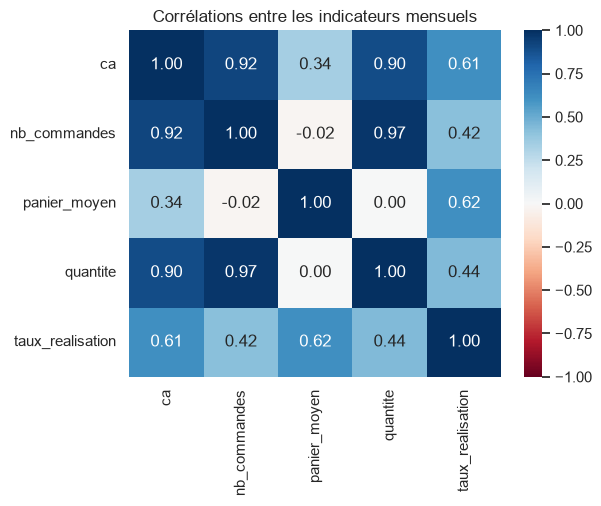

In [38]:
colonnes = ["ca", "nb_commandes", "panier_moyen", "quantite", "taux_realisation"]
correlations = indicateurs[colonnes].corr()

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="RdBu", vmin=-1, vmax=1, ax=ax)
ax.set_title("Corrélations entre les indicateurs mensuels")


In [39]:
# Vérification
assert correlations.shape == (5, 5), "la matrice doit croiser les 5 colonnes demandées"
assert round(correlations.loc["ca", "nb_commandes"], 2) == 0.92, "calcule la matrice avec la méthode corr"
assert len(ax.texts) == 25, "écris la valeur de chaque case avec annot=True"
print("Question 2.8 : OK")


Question 2.8 : OK


**Réponse** : Le nombre de commandes (0,92), suivi de près par la quantité (0,90) : le chiffre d'affaires d'un mois dépend d'abord du nombre de commandes. Le panier moyen n'est pas lié au nombre de commandes (-0,02) : un mois avec beaucoup de commandes n'a pas des commandes plus grosses ou plus petites que les autres. Une corrélation mesure une liaison, pas une cause.

### Pour aller plus loin 2.9

Les clients fidèles passent-ils de plus grosses commandes ? Compare les deux distributions du montant avec `sns.histplot` et `hue="client_fidele"`, dans `fig, ax = plt.subplots(figsize=(8, 4))`. Les deux groupes n'ont pas la même taille : pour les comparer, trace des densités (`stat="density"`) normalisées séparément (`common_norm=False`). Confirme avec la médiane et la moyenne de chaque groupe.

**Résultat attendu** :

![Résultat attendu de la question 2.9](attendus/q2_9.png)

,median,mean
client_fidele,,
False,99.5,186.72
True,113.8,189.46


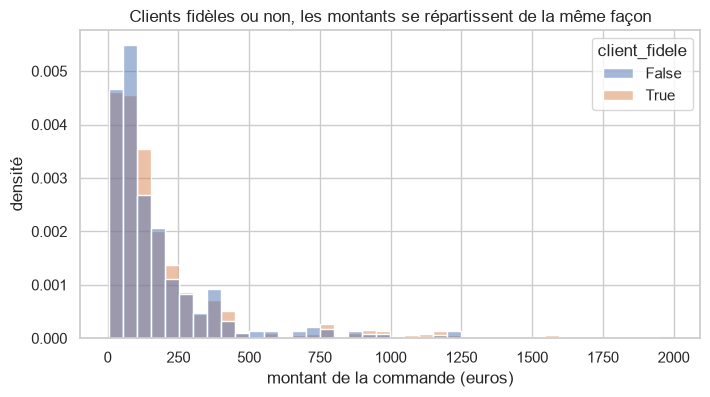

In [40]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=ventes, x="montant", hue="client_fidele", bins=40, stat="density", common_norm=False, ax=ax)
ax.set_title("Clients fidèles ou non, les montants se répartissent de la même façon")
ax.set_xlabel("montant de la commande (euros)")
ax.set_ylabel("densité")

ventes.groupby("client_fidele")["montant"].agg(["median", "mean"]).round(2)


**Réponse** : Pas vraiment : les deux distributions ont presque la même forme. La médiane des clients fidèles est un peu plus élevée (113,80 euros contre 99,50 euros), mais les moyennes sont presque égales (189,46 euros contre 186,72 euros).

### Pour aller plus loin 2.10

Trace `sns.barplot(data=ventes, x="region", y="montant", ax=ax)`, sans préciser `estimator`, dans `fig, ax = plt.subplots(figsize=(8, 4))`. Que représentent la hauteur des barres et les traits verticaux ? Retrouve la hauteur des barres avec un `groupby`.

region
Auvergne-Rhône-Alpes    171.58
Bretagne                196.55
Hauts-de-France         167.09
Nouvelle-Aquitaine      229.53
Occitanie               174.72
Île-de-France           189.82
Name: montant, dtype: float64

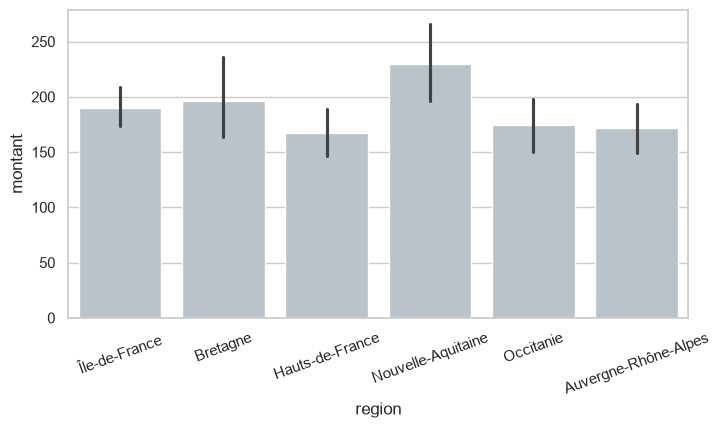

In [41]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=ventes, x="region", y="montant", color="#B8C2CC", ax=ax)
ax.tick_params(axis="x", labelrotation=20)

ventes.groupby("region")["montant"].mean().round(2)


**Réponse** : Par défaut, `barplot` affiche la **moyenne** de chaque groupe : la hauteur d'une barre est le montant moyen d'une commande dans la région, pas un total. Le trait vertical est l'intervalle de confiance à 95 % de cette moyenne : plus il est long, moins la moyenne est précise, ce qui arrive quand une région a peu de commandes ou des montants très dispersés.

## Partie 3 : plotly

*À faire après la section 4 du cours : plotly.*

Les graphiques plotly sont interactifs : survole-les, zoome, clique sur la légende. Les vérifications inspectent l'objet renvoyé par plotly express, que tu ranges dans la variable indiquée.

### Question 3.1

Crée avec `px.line` un graphique interactif du chiffre d'affaires mensuel par région, avec des marqueurs et un titre, dans une variable `fig_ca`. Ajoute dans l'info-bulle le nombre de commandes et le taux de réalisation formaté en pourcentage (`hover_data`), et remplace les noms de colonnes par des libellés lisibles avec `labels`. Termine par `fig_ca.show()`.

In [42]:
fig_ca = px.line(
    indicateurs,
    x="mois",
    y="ca",
    color="region",
    markers=True,
    hover_data={"nb_commandes": True, "taux_realisation": ":.0%"},
    labels={
        "ca": "chiffre d'affaires",
        "mois": "",
        "region": "région",
        "nb_commandes": "commandes",
        "taux_realisation": "objectif atteint",
    },
    title="Chiffre d'affaires mensuel par région",
)
fig_ca.update_layout(yaxis_title="chiffre d'affaires (euros)", template="simple_white")
fig_ca.show()


In [43]:
# Vérification
assert len(fig_ca.data) == 6, "il faut une courbe par région : color=\"region\""
assert fig_ca.layout.title.text, "ajoute un titre avec title=..."
assert fig_ca.data[0].customdata is not None and fig_ca.data[0].customdata.shape[1] >= 2, "ajoute le nombre de commandes et le taux de réalisation à l'info-bulle avec hover_data"
info_bulle = fig_ca.data[0].hovertemplate
assert "region=" not in info_bulle and "ca=" not in info_bulle, "remplace les noms de colonnes par des libellés lisibles avec labels"
print("Question 3.1 : OK")


Question 3.1 : OK


### Question 3.2

Avec `px.bar`, trace le chiffre d'affaires mensuel en barres empilées, une couleur par région (`color="region"`), avec un titre et des libellés lisibles, dans une variable `fig_barres`.

Survole les barres, puis clique sur une région dans la légende pour la masquer : que deviennent les barres ? Qu'apporte ce graphique par rapport à celui de la question 3.1 ?

In [44]:
fig_barres = px.bar(
    indicateurs,
    x="mois",
    y="ca",
    color="region",
    labels={"ca": "chiffre d'affaires (euros)", "mois": "", "region": "région"},
    title="Chiffre d'affaires mensuel et part de chaque région",
    template="simple_white",
)
fig_barres.show()


In [45]:
# Vérification
assert len(fig_barres.data) == 6, "il faut une couleur par région : color=\"region\""
assert all(trace.type == "bar" for trace in fig_barres.data), "utilise px.bar"
assert fig_barres.layout.title.text, "ajoute un titre"
print("Question 3.2 : OK")


Question 3.2 : OK


**Réponse** : Quand on masque une région, les barres se recalculent sans elle. Les barres empilées montrent à la fois le total du mois et sa décomposition par région ; les courbes de la question 3.1 comparent mieux l'évolution de chaque région.

### Question 3.3

Avec `px.box`, trace la distribution du montant des commandes par catégorie, avec un titre, dans une variable `fig_boites`. Ajoute le produit et la quantité à l'info-bulle (`hover_data=["produit", "quantite"]`). Survole les points les plus hauts de la catégorie Bureau : retrouves-tu les commandes identifiées à la question 2.2 ?

In [46]:
fig_boites = px.box(
    ventes,
    x="categorie",
    y="montant",
    hover_data=["produit", "quantite"],
    labels={"categorie": "", "montant": "montant de la commande (euros)"},
    title="Montant des commandes par catégorie",
    template="simple_white",
)
fig_boites.show()


In [47]:
# Vérification
assert fig_boites.data[0].type == "box", "utilise px.box"
assert fig_boites.data[0].customdata is not None, "ajoute le produit et la quantité à l'info-bulle avec hover_data"
print("Question 3.3 : OK")


Question 3.3 : OK


**Réponse** : Oui : au survol, les points au-dessus de 1 000 euros sont des bureaux assis-debout, commandés par 3 à 5, et des chaises ergonomiques, commandées par 5. L'info-bulle permet d'identifier une valeur extrême sans écrire de filtre.

### Question 3.4

Crée un nuage de points interactif du chiffre d'affaires en fonction du nombre de commandes, avec une couleur par région et une taille de point selon la quantité vendue (`size="quantite"`), dans une variable `fig_nuage`. Ajoute le mois à l'info-bulle, au format mois et année (`hover_data={"mois": "|%m/%Y"}`), des libellés lisibles et un titre qui énonce le message.

Survole les points en haut à droite, ceux qui s'écartaient de la tendance à la question 1.6 : à quelle région et à quels mois correspondent-ils ?

In [48]:
fig_nuage = px.scatter(
    indicateurs,
    x="nb_commandes",
    y="ca",
    color="region",
    size="quantite",
    hover_data={"mois": "|%m/%Y"},
    labels={"nb_commandes": "nombre de commandes", "ca": "chiffre d'affaires", "region": "région", "quantite": "quantité"},
    title="Plus de commandes, plus de chiffre d'affaires",
    template="simple_white",
)
fig_nuage.show()


In [49]:
# Vérification
assert len(fig_nuage.data) == 6, "il faut une couleur par région : color=\"region\""
assert fig_nuage.data[0].marker.size is not None, "la taille des points doit dépendre de la quantité : size=\"quantite\""
assert fig_nuage.layout.title.text, "ajoute un titre"
print("Question 3.4 : OK")


Question 3.4 : OK


**Réponse** : À l'Île-de-France, pour ses six mois à plus de 70 commandes : janvier, mars, avril, mai, juin et septembre. Son chiffre d'affaires y plafonne autour de 16 k€, car son panier moyen baisse quand le nombre de commandes augmente : 232 euros en avril pour 71 commandes, 160 euros en septembre pour 100 commandes.

### Question 3.5

Exporte le graphique de la question 3.1 en `ca_mensuel_regions.html` avec les options par défaut, puis en `ca_mensuel_regions_cdn.html` avec `include_plotlyjs="cdn"`. Affiche la taille des deux fichiers en kilo-octets (`Path(...).stat().st_size` donne la taille en octets), et ouvre-les dans ton navigateur. Lequel choisirais-tu pour l'envoyer par mail ?

In [50]:
fig_ca.write_html("ca_mensuel_regions.html")
fig_ca.write_html("ca_mensuel_regions_cdn.html", include_plotlyjs="cdn")

for fichier in ["ca_mensuel_regions.html", "ca_mensuel_regions_cdn.html"]:
    print(fichier, round(Path(fichier).stat().st_size / 1000), "Ko")


ca_mensuel_regions.html 4832 Ko
ca_mensuel_regions_cdn.html 16 Ko


In [51]:
# Vérification
assert Path("ca_mensuel_regions.html").exists(), "exporte fig_ca en ca_mensuel_regions.html"
assert Path("ca_mensuel_regions_cdn.html").exists(), "exporte fig_ca en ca_mensuel_regions_cdn.html, avec include_plotlyjs=\"cdn\""
assert Path("ca_mensuel_regions.html").stat().st_size > 1_000_000, "le fichier par défaut embarque la bibliothèque plotly : il doit peser plusieurs Mo"
assert Path("ca_mensuel_regions_cdn.html").stat().st_size < 100_000, "avec include_plotlyjs=\"cdn\", le fichier doit peser moins de 100 Ko"
print("Question 3.5 : OK")


Question 3.5 : OK


**Réponse** : Le fichier par défaut pèse près de 5 Mo, car il embarque toute la bibliothèque plotly ; la version `cdn` ne pèse qu'une quinzaine de kilo-octets, mais elle télécharge plotly à l'ouverture et a donc besoin d'une connexion internet. Pour un mail, on choisit la version autonome : elle s'ouvre partout, même sans connexion, et 5 Mo restent acceptables en pièce jointe.

### Pour aller plus loin 3.6

Avec `px.histogram`, trace le nombre de commandes par jour de la semaine (colonne `jour`), dans une variable `fig_jours`. Les jours doivent apparaître dans l'ordre du calendrier, du lundi au dimanche : passe la liste des jours dans cet ordre au paramètre `category_orders={"jour": jours}`. Pourquoi ne pas trier ces barres par valeur, comme on l'a fait pour les régions ?

In [52]:
jours = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]

fig_jours = px.histogram(
    ventes,
    x="jour",
    category_orders={"jour": jours},
    labels={"jour": ""},
    title="Les commandes se concentrent du lundi au vendredi",
    template="simple_white",
)
fig_jours.update_layout(yaxis_title="nombre de commandes")
fig_jours.show()


In [53]:
# Vérification
assert list(fig_jours.layout.xaxis.categoryarray) == jours, "les jours doivent suivre l'ordre du calendrier : category_orders"
print("Question 3.6 : OK")


Question 3.6 : OK


**Réponse** : Les jours de la semaine ont un ordre naturel, comme les mois : on le garde, car c'est lui qui permet de lire le graphique. Trier par valeur mélangerait le week-end et la semaine. Ici, on voit tout de suite que l'activité baisse le samedi et presque s'arrête le dimanche.

## Partie 4 : corriger des graphiques trompeurs

*À faire après la section 5 du cours : bonnes pratiques de dataviz.*

Chaque cellule de cette partie contient le code d'un graphique mal construit. Pour chacun :

1. exécute la cellule telle quelle et observe le graphique ;
2. explique le défaut dans la cellule de réponse : en quoi le graphique trompe-t-il ou gêne-t-il la lecture ?
3. modifie le code de la cellule pour obtenir le résultat attendu, en gardant les noms `fig` et `ax` (ou `axes`), puis exécute la vérification.

### Question 4.1

Le graphique suivant compare le panier moyen des régions. Corrige-le pour qu'il ne trompe plus, et donne-lui un titre qui énonce le message.

**Résultat attendu** :

![Résultat attendu de la question 4.1](attendus/q4_1.png)

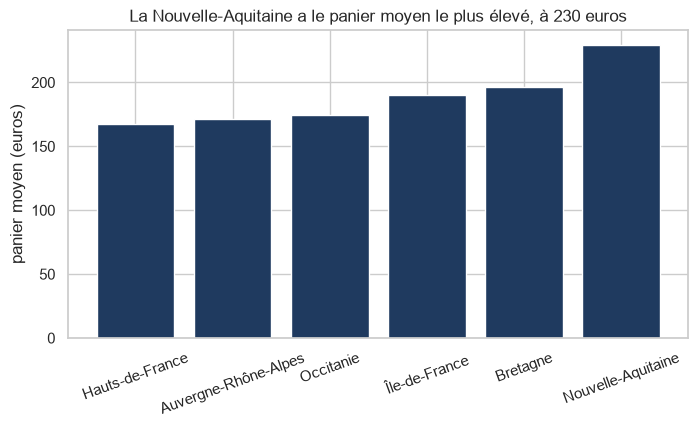

In [54]:
panier_region = ventes.groupby("region")["montant"].mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(panier_region.index, panier_region.values, color="#1F3A5F")
ax.set_title("La Nouvelle-Aquitaine a le panier moyen le plus élevé, à 230 euros")
ax.set_ylabel("panier moyen (euros)")
ax.tick_params(axis="x", labelrotation=20)


In [55]:
# Vérification
assert len(ax.patches) == 6, "il faut une barre par région"
assert ax.get_ylim()[0] == 0, "l'axe d'un graphique en barres doit partir de zéro"
print("Question 4.1 : OK")


Question 4.1 : OK


**Réponse** : L'axe vertical commence à 150 euros : la longueur des barres ne représente plus les valeurs. La barre de la Nouvelle-Aquitaine paraît près de cinq fois plus haute que celle des Hauts-de-France, alors que son panier moyen n'est que 37 % plus élevé (230 euros contre 167 euros). Un graphique en barres part toujours de zéro.

### Question 4.2

Le graphique suivant doit montrer quels produits sont les plus commandés. Corrige-le pour qu'on les trouve d'un coup d'œil, et donne-lui un titre qui énonce le message.

**Résultat attendu** :

![Résultat attendu de la question 4.2](attendus/q4_2.png)

Text(0.5, 0, 'nombre de commandes')

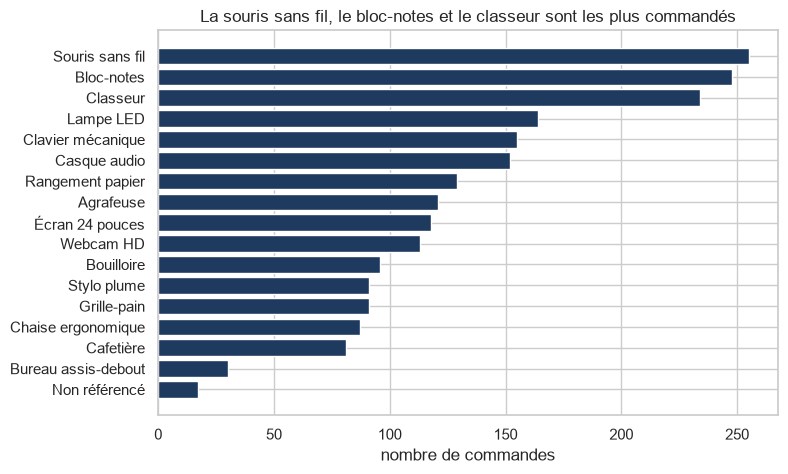

In [56]:
commandes_produit = ventes["produit"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(commandes_produit.index, commandes_produit.values, color="#1F3A5F")
ax.set_title("La souris sans fil, le bloc-notes et le classeur sont les plus commandés")
ax.set_xlabel("nombre de commandes")


In [57]:
# Vérification
largeurs = [barre.get_width() for barre in ax.patches]
assert len(largeurs) == 17, "il faut une barre par produit"
assert largeurs == sorted(largeurs), "trie les barres pour que le produit le plus commandé soit en haut"
print("Question 4.2 : OK")


Question 4.2 : OK


**Réponse** : Les barres suivent l'ordre alphabétique des produits, qui n'a aucun rapport avec la question posée : pour trouver les produits les plus commandés, il faut comparer des barres dispersées. Triées par valeur, elles se lisent comme un classement : la souris sans fil, le bloc-notes et le classeur arrivent en tête.

### Question 4.3

Le graphique suivant présente le chiffre d'affaires par catégorie. Corrige ses couleurs : une seule couleur pour mettre en évidence la catégorie qui fait le plus de chiffre d'affaires, du gris pour les autres, et pas de légende. Donne-lui un titre qui énonce le message.

**Résultat attendu** :

![Résultat attendu de la question 4.3](attendus/q4_3.png)

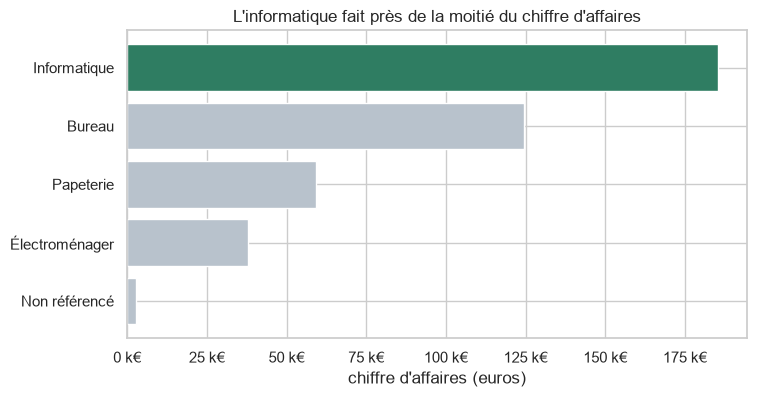

In [58]:
ca_categorie = ventes.groupby("categorie")["montant"].sum().sort_values()
couleurs_categorie = ["#2F7D62" if c == ca_categorie.idxmax() else "#B8C2CC" for c in ca_categorie.index]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(ca_categorie.index, ca_categorie.values, color=couleurs_categorie)
ax.set_title("L'informatique fait près de la moitié du chiffre d'affaires")
ax.set_xlabel("chiffre d'affaires (euros)")
ax.xaxis.set_major_formatter(milliers)


In [59]:
# Vérification
assert len(ax.patches) == 5, "il faut une barre par catégorie"
assert len({barre.get_facecolor() for barre in ax.patches}) <= 2, "deux couleurs au plus : une pour mettre en évidence, du gris pour le reste"
assert ax.get_legend() is None, "la légende répète les libellés de l'axe : supprime-la"
print("Question 4.3 : OK")


Question 4.3 : OK


**Réponse** : Les cinq couleurs ne portent aucune information : chaque catégorie est déjà nommée sur l'axe, et la légende répète les mêmes libellés en cachant une partie du graphique. Elles attirent l'œil partout à la fois, et opposent du rouge et du vert, que les daltoniens distinguent mal. Avec une couleur pour le message et du gris pour le reste, le regard va droit à l'informatique.

### Question 4.4

Les deux graphiques suivants comparent l'activité de l'Île-de-France et de la Bretagne. Corrige-les pour que la comparaison soit juste : la même échelle verticale pour les deux, qui part de zéro.

**Résultat attendu** :

![Résultat attendu de la question 4.4](attendus/q4_4.png)

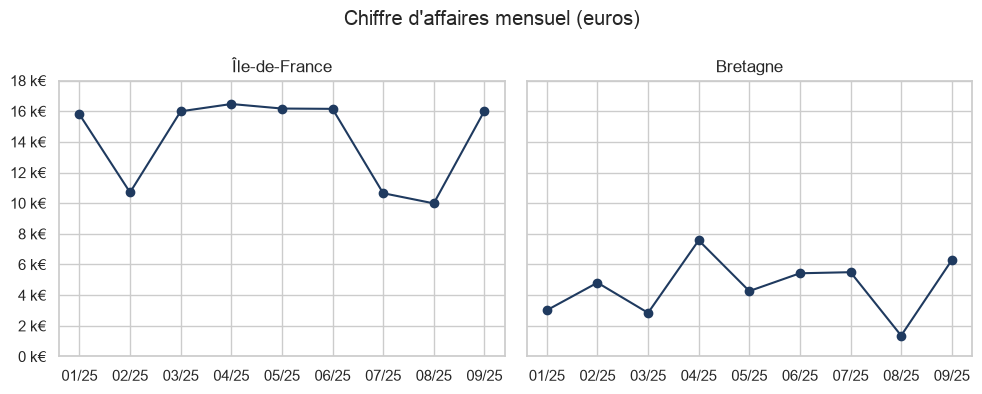

In [60]:
idf = indicateurs[indicateurs["region"] == "Île-de-France"]
bretagne = indicateurs[indicateurs["region"] == "Bretagne"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
axes[0].plot(etiquettes, idf["ca"], marker="o", color="#1F3A5F")
axes[0].set_title("Île-de-France")
axes[0].yaxis.set_major_formatter(milliers)
axes[0].set_ylim(0, 18000)
axes[1].plot(etiquettes, bretagne["ca"], marker="o", color="#1F3A5F")
axes[1].set_title("Bretagne")
fig.suptitle("Chiffre d'affaires mensuel (euros)")
fig.tight_layout()


In [61]:
# Vérification
assert len(fig.axes) == 2, "garde les deux graphiques côte à côte"
assert axes[0].get_ylim() == axes[1].get_ylim(), "les deux graphiques doivent avoir la même échelle verticale : sharey=True"
assert axes[0].get_ylim()[0] == 0, "l'échelle verticale doit partir de zéro"
print("Question 4.4 : OK")


Question 4.4 : OK


**Réponse** : Chaque graphique a sa propre échelle verticale : de 10 à 17 k€ environ pour l'Île-de-France, de 1 à 8 k€ pour la Bretagne. Les deux courbes semblent du même niveau, alors que l'Île-de-France vend chaque mois de 2 à 7 fois plus que la Bretagne. Avec une échelle commune, l'écart saute aux yeux.

### Question 4.5

Le graphique suivant montre la part de chaque produit dans le chiffre d'affaires. Remplace le camembert par des barres horizontales triées, la plus grande en haut, et affiche la part de chaque produit en pourcentage au bout de sa barre (`ax.bar_label`), en prolongeant l'axe horizontal jusqu'à 75 000 euros. Donne-lui un titre qui énonce le message.

**Résultat attendu** :

![Résultat attendu de la question 4.5](attendus/q4_5.png)

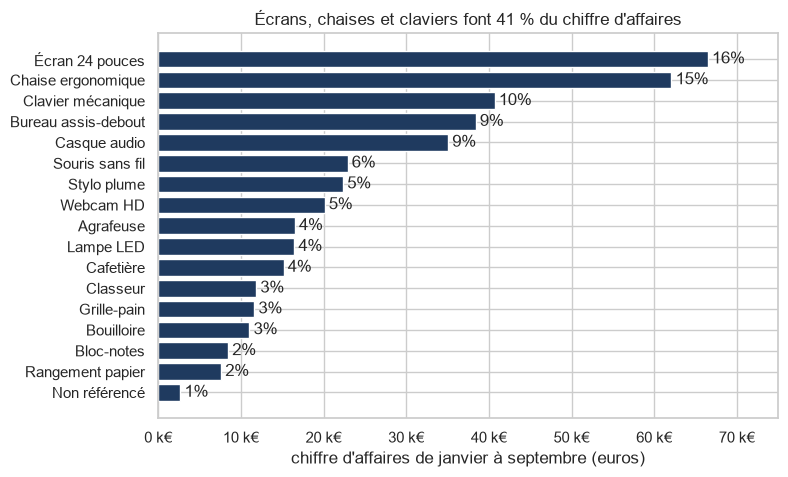

In [62]:
ca_produit = ventes.groupby("produit")["montant"].sum().sort_values()
parts = ca_produit / ca_produit.sum()

fig, ax = plt.subplots(figsize=(8, 5))
barres = ax.barh(ca_produit.index, ca_produit.values, color="#1F3A5F")
ax.bar_label(barres, labels=[f"{p:.0%}" for p in parts], padding=3)
ax.set_title("Écrans, chaises et claviers font 41 % du chiffre d'affaires")
ax.set_xlabel("chiffre d'affaires de janvier à septembre (euros)")
ax.set_xlim(0, 75000)
ax.xaxis.set_major_formatter(milliers)


In [63]:
# Vérification
from matplotlib.patches import Rectangle

assert all(isinstance(barre, Rectangle) for barre in ax.patches), "remplace le camembert (ax.pie) par des barres horizontales (ax.barh)"
largeurs = [barre.get_width() for barre in ax.patches]
assert len(largeurs) == 17, "il faut une barre par produit"
assert largeurs == sorted(largeurs), "trie les barres, la plus grande en haut"
assert len(ax.texts) == 17, "affiche la part de chaque produit au bout de sa barre avec ax.bar_label"
print("Question 4.5 : OK")


Question 4.5 : OK


**Réponse** : Avec 17 parts, les angles sont trop proches pour être comparés, les petites parts sont illisibles et les libellés se chevauchent. Les barres triées classent les produits d'un coup d'œil et affichent la part de chacun : l'écran 24 pouces arrive en tête avec 16 % du chiffre d'affaires.

### Pour aller plus loin 4.6

Le graphique suivant superpose le nombre de commandes et le panier moyen de chaque mois, avec deux axes verticaux (`ax.twinx()`). Remplace-le par deux graphiques l'un au-dessus de l'autre, qui partagent l'axe des mois : `fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)`. Donne un titre à chacun.

**Résultat attendu** :

![Résultat attendu de la question 4.6](attendus/q4_6.png)

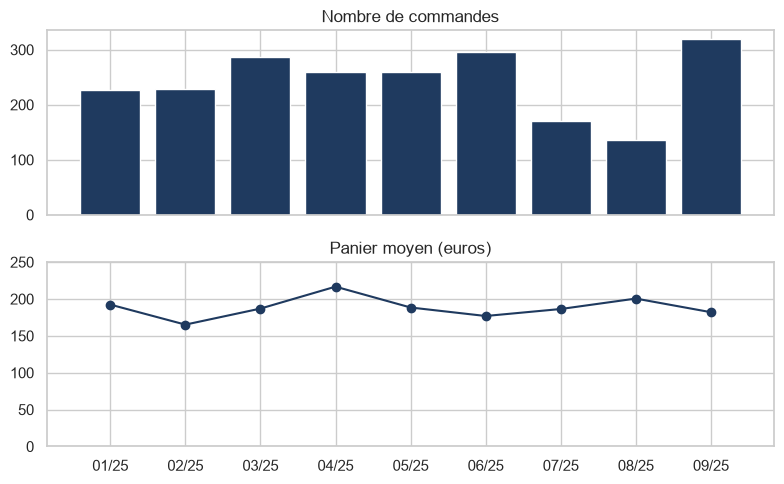

In [64]:
panier_mensuel = mensuel / commandes

fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
axes[0].bar(etiquettes, commandes.values, color="#1F3A5F")
axes[0].set_title("Nombre de commandes")
axes[1].plot(etiquettes, panier_mensuel.values, color="#1F3A5F", marker="o")
axes[1].set_ylim(0, 250)
axes[1].set_title("Panier moyen (euros)")
fig.tight_layout()


In [65]:
# Vérification
assert len(fig.axes) == 2, "il faut deux graphiques"
assert fig.axes[0].get_position().bounds != fig.axes[1].get_position().bounds, "les deux graphiques doivent être séparés, l'un au-dessus de l'autre, et non superposés"
print("Question 4.6 : OK")


Question 4.6 : OK


**Réponse** : Les deux échelles verticales sont choisies arbitrairement : en les modifiant, on peut faire croire que le panier moyen suit le nombre de commandes, ou qu'il évolue en sens inverse. Ici, l'échelle de droite, de 160 à 220 euros, fait paraître énormes des variations de quelques dizaines d'euros. Deux graphiques séparés, alignés sur les mêmes mois, montrent chaque grandeur sur sa propre échelle sans suggérer de lien : le panier moyen reste stable autour de 190 euros, c'est le nombre de commandes qui varie.

### Pour aller plus loin 4.7

La heatmap suivante utilise une palette rouge, jaune et vert. Remplace-la par une palette lisible par les daltoniens, toujours centrée sur 100 % : tu dois retrouver la heatmap de la question 2.7.

Text(0.5, 1.0, "Taux de réalisation de l'objectif mensuel")

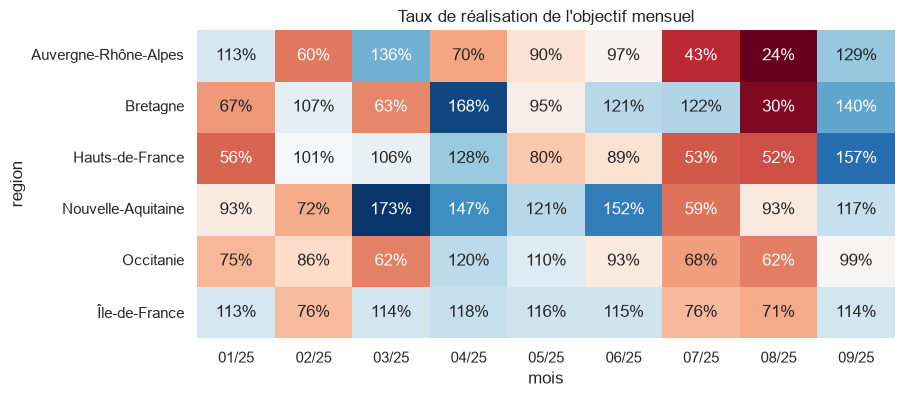

In [66]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(taux, annot=True, fmt=".0%", cmap="RdBu", center=1, cbar=False, ax=ax)
ax.set_title("Taux de réalisation de l'objectif mensuel")


In [67]:
# Vérification
assert "Gn" not in ax.collections[0].get_cmap().name, "choisis une palette sans vert, par exemple RdBu"
print("Question 4.7 : OK")


Question 4.7 : OK


**Réponse** : La palette `RdYlGn` oppose le rouge et le vert, que confondent les personnes atteintes de la forme la plus fréquente de daltonisme : elles ne distinguent plus les mois au-dessus de l'objectif de ceux en dessous. `RdBu` oppose le rouge et le bleu, lisibles par tous.

## Partie 5 : tableau de bord

*À faire après la section 6 du cours : construire un tableau de bord.*

Construis 4 à 5 graphiques qui, ensemble, racontent l'activité commerciale de janvier à septembre 2025 à la direction. Tu peux reprendre et améliorer ceux des parties précédentes.

Pour chaque graphique, respecte la structure ci-dessous : la question à laquelle il répond, le graphique, et ce qu'il faut en retenir en une ou deux phrases. Les questions proposées sont celles que se pose la direction ; tu peux les remplacer par d'autres si tu les juges plus utiles.

Avant de finir, vérifie chaque graphique avec cette liste :

- le type de graphique correspond à la question posée ;
- le titre énonce le message ;
- les axes sont nommés, avec leur unité, et les nombres sont lisibles ;
- les barres sont triées et partent de zéro ;
- la couleur sert à mettre en évidence, pas à décorer ;
- la palette est lisible par les daltoniens.

### Graphique 1

**Question** : comment le chiffre d'affaires a-t-il évolué depuis janvier ?

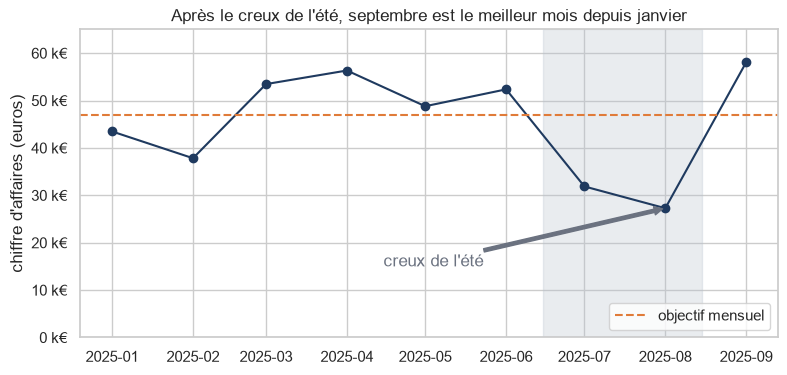

In [68]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(mensuel.index, mensuel.values, marker="o", color="#1F3A5F")
ax.axvspan(pd.to_datetime("2025-06-15"), pd.to_datetime("2025-08-15"), color="#B8C2CC", alpha=0.3)
ax.annotate(
    "creux de l'été",
    xy=(mensuel.index[7], mensuel.iloc[7]),
    xytext=(pd.to_datetime("2025-04-15"), 15000),
    arrowprops={"arrowstyle": "simple", "color": "#6B7280"},
    color="#6B7280",
)
ax.axhline(objectif_total, color="#E07B39", linestyle="--", label="objectif mensuel")
ax.set_title("Après le creux de l'été, septembre est le meilleur mois depuis janvier")
ax.set_ylabel("chiffre d'affaires (euros)")
ax.set_ylim(0, 65000)
ax.yaxis.set_major_formatter(milliers)
ax.legend(loc="lower right")


**Ce qu'on retient** : L'activité oscille entre 38 et 56 k€ par mois au premier semestre, chute presque de moitié en juillet et août, puis repart fortement en septembre (58 k€). L'objectif de 47 000 euros est dépassé cinq mois sur neuf.

### Graphique 2

**Question** : quelles régions portent l'activité ?

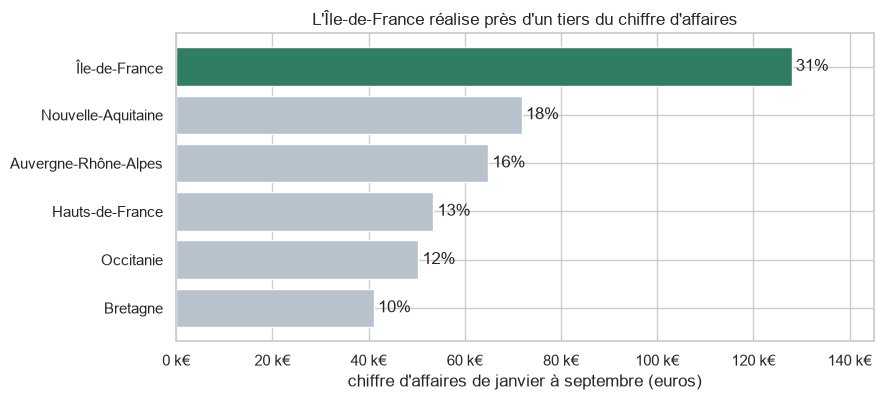

In [69]:
fig, ax = plt.subplots(figsize=(9, 4))
barres = ax.barh(par_region.index, par_region.values, color=couleurs)
ax.bar_label(barres, labels=[f"{v / par_region.sum():.0%}" for v in par_region.values], padding=3)
ax.set_title("L'Île-de-France réalise près d'un tiers du chiffre d'affaires")
ax.set_xlabel("chiffre d'affaires de janvier à septembre (euros)")
ax.set_xlim(0, 145000)
ax.xaxis.set_major_formatter(milliers)


**Ce qu'on retient** : L'Île-de-France pèse 31 % du chiffre d'affaires, près du double de la deuxième région, la Nouvelle-Aquitaine (18 %). La Bretagne ferme la marche avec 10 %.

### Graphique 3

**Question** : les régions atteignent-elles leurs objectifs ?

Text(76.53480360243056, 0.5, '')

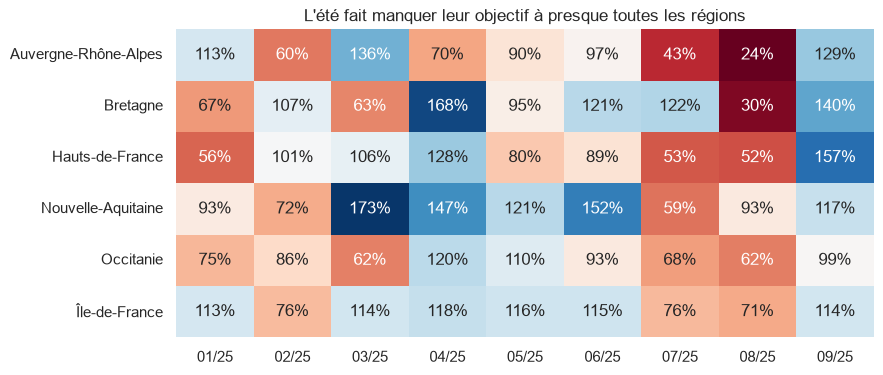

In [70]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(taux, annot=True, fmt=".0%", cmap="RdBu", center=1, cbar=False, ax=ax)
ax.set_title("L'été fait manquer leur objectif à presque toutes les régions")
ax.set_xlabel("")
ax.set_ylabel("")


**Ce qu'on retient** : L'Île-de-France atteint son objectif 6 mois sur 9, la Bretagne et la Nouvelle-Aquitaine 5 mois, l'Occitanie seulement 2. En juillet et août, presque toutes les régions sont en dessous : des objectifs ajustés à la saisonnalité seraient plus justes.

### Graphique 4

**Question** : comment chaque région a-t-elle évolué mois après mois ? C'est le graphique interactif principal : exporte-le en `ca_mensuel_regions.html`.

In [71]:
fig_ca.update_layout(title="Chiffre d'affaires mensuel par région : survolez pour voir le taux d'objectif")
fig_ca.write_html("ca_mensuel_regions.html")
fig_ca.show()


In [72]:
# Vérification
assert Path("ca_mensuel_regions.html").exists(), "exporte le graphique interactif principal en ca_mensuel_regions.html"
print("Graphique 4 : OK")


Graphique 4 : OK


**Ce qu'on retient** : Le graphique interactif permet de suivre une région en masquant les autres dans la légende, et d'afficher au survol le nombre de commandes et le taux de réalisation de l'objectif. C'est lui qu'on envoie à la direction, en HTML.

### Graphique 5 (facultatif)

**Question** : à toi de la choisir, par exemple : quelles catégories font le chiffre d'affaires ?

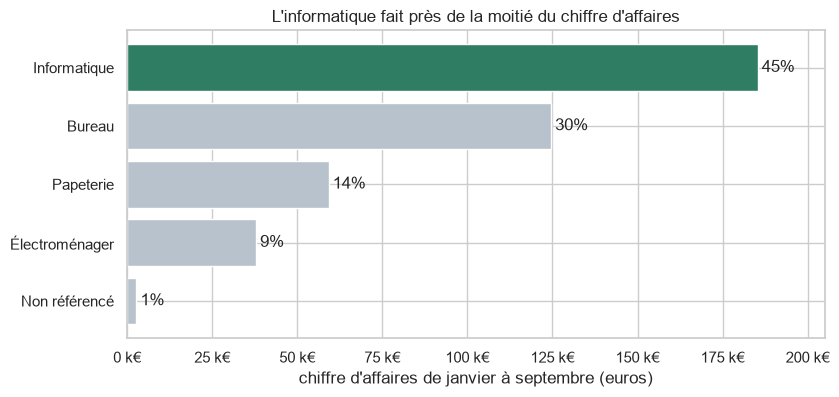

In [73]:
fig, ax = plt.subplots(figsize=(9, 4))
barres = ax.barh(ca_categorie.index, ca_categorie.values, color=couleurs_categorie)
ax.bar_label(barres, labels=[f"{v / ca_categorie.sum():.0%}" for v in ca_categorie.values], padding=3)
ax.set_title("L'informatique fait près de la moitié du chiffre d'affaires")
ax.set_xlabel("chiffre d'affaires de janvier à septembre (euros)")
ax.set_xlim(0, 205000)
ax.xaxis.set_major_formatter(milliers)


**Ce qu'on retient** : L'informatique pèse 45 % du chiffre d'affaires, le mobilier de bureau 30 %. La papeterie, première catégorie en quantité vendue, ne représente que 14 % du chiffre d'affaires.

## Avant de rendre

- Les fichiers `activite_mensuelle.png` et `ca_mensuel_regions.html` sont présents dans le dossier du TP, et le fichier HTML s'ouvre dans un navigateur en restant interactif.
- Toutes les cellules de vérification affichent `OK`.
- Chaque graphique du tableau de bord a sa question et son message.
- Le notebook s'exécute sans erreur de haut en bas : menu *Kernel*, puis *Restart Kernel and Run All Cells*.